# LAB | A/B Testing in Python

### Challenge 1: 🚀 *Comparing Two Website Versions Using Hypothesis Testing*  

### **Objective**: 
Perform an A/B test to determine if a new webpage design (`Version B`) leads to a higher **click-through rate (CTR)** than the original (`Version A`).  

#### 📌 **Project Overview**  
We’ll:  
1. **Simulate** A/B test data (users & clicks).  
2. **Analyze** the results using statistical tests.  
3. **Conclude** whether `Version B` performs better.  



### **Problem Statement**  
You are a data analyst at an e-commerce company. The team wants to test if a new webpage design (`Version B`) increases click-through rates (CTR) compared to the original (`Version A`).  

### **Tasks**  
1. **Simulate Data**:  
   - Generate synthetic data for `Version A` (1000 visitors, 150 clicks) and `Version B` (1050 visitors, 180 clicks).  
2. **Statistical Test**:  
   - Perform a **Statistical Test** to compare CTRs.  
3. **Interpretation**:  
   - Determine if the difference is statistically significant (use α = 0.05).  
4. **Visualization**:  
   - Plot the CTRs for both versions using appropriate chart.  

**Deliverables**:  
- Code for simulation, testing, and visualization.  
- Written conclusion (1–2 sentences) on whether `Version B` performs better.  

#### 🛠 **Setup & Data Generation**  
First, let’s create synthetic data for the experiment.  


In [57]:
### Import Libraries
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

> Simulate User Data, We’ll assume:

- Version A: 1000 visitors, 150 clicks.

- Version B: 1050 visitors, 180 clicks.

In [58]:
# Simulate data
np.random.seed(42)
visitors_a = 1000
clicks_a = 150
visitors_b = 1050
clicks_b = 180

In [59]:
# To Calculate Click-Through Rate, divide the total number of clicks by the total number of visitors. 
# To get the percentage, you need to multiply this number by 100. 
# This is the rate of how many users both viewed and clicked your ad.
ctr_a = (clicks_a / visitors_a)*100
ctr_b = (clicks_b / visitors_b)*100

In [60]:
ctr_a

15.0

In [61]:
ctr_b

17.142857142857142

In [62]:
visitors_A = 1000
clicks_A = 150
visitors_B = 1050
clicks_B = 180

non_clicks_A = visitors_A - clicks_A
non_clicks_B = visitors_B - clicks_B

data = pd.DataFrame({
    "Version":["A", "B"],
    "Visitors": [visitors_A, visitors_B],
    "Clicks": [clicks_A, clicks_B],
    "Non-Clicks": [non_clicks_A, non_clicks_B]})

contingency_table = np.array([[clicks_A, non_clicks_A],[clicks_B, non_clicks_B]])
contingency_table

array([[150, 850],
       [180, 870]])

In [63]:
data

,Version,Visitors,Clicks,Non-Clicks
0,A,1000,150,850
1,B,1050,180,870


📊 Perform A/B Test
We’ll use a Chi-Square Test to compare proportions.

- Hypotheses

In [1]:
# Null Hypothesis (H₀): There is no difference between the CTRs of Version A and Version B. CTR_a=CTR_b
# Alternative Hypothesis (H1): There is a difference between the CTRs of Version A and Version B. CTR_a != CTR_b


- Run the Test

In [67]:
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)
p_value

np.float64(0.20785388523374115)

In [68]:
chi2_statistic, chi2_p_value, _, _ = stats.chi2_contingency(contingency_table)
chi2_statistic, chi2_p_value

(np.float64(1.586311673629987), np.float64(0.20785388523374115))

> Interpret Results

In [69]:
# p_value of 0.21, over 0.05, so there isn't enough evidence to reject the null hypthesis that there is no difference between the
# the CTRs of Version A and Version B, meaning there is a difference between them

print(f"P-value: {p_value}")
alpha = 0.05
if p_value < alpha:
    print("There is enough evidence to reject the null hypothesis. Statistically significant difference in CTR between Version A and B.")
else: print("There is not enough evidence to reject the null hypothesis. No statistically significant difference in CTR between Version A and B.")


P-value: 0.20785388523374115
There is not enough evidence to reject the null hypothesis. No statistically significant difference in CTR between Version A and B.


📈 Visualization

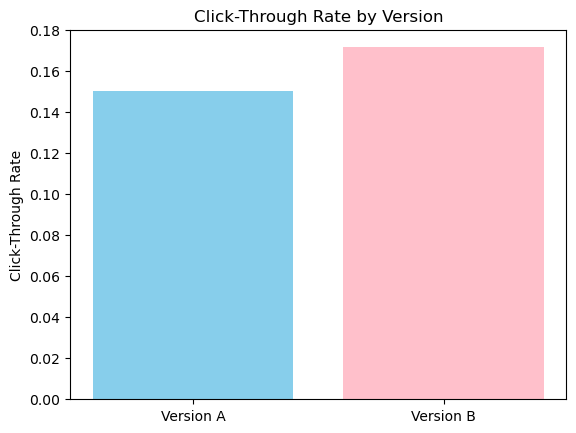

In [70]:
# Bar chart for Clicks
ctr_a = clicks_A / visitors_A
ctr_b = clicks_B / visitors_B

plt.bar(["Version A", "Version B"], [ctr_a, ctr_b], color=["skyblue", "pink"])
plt.ylabel("Click-Through Rate")
plt.title("Click-Through Rate by Version")
plt.show()

## Challenge 2: 🚀 A/B Testing Challenge with Real Data

#### **Objective**:  
1. Analyze **real A/B test data** (from Kaggle) to compare conversion rates.  
2. Use **bootstrapping** to estimate confidence intervals.  

---

#### 📌 **Project Overview**  
We’ll:  
1. **Load real A/B test data** (user sessions and conversions).  
2. **Compare conversion rates** using statistical tests.  
3. **Apply bootstrapping** to validate results.  



### **Problem Statement**  
Use the [Kaggle Marketing A/B Test dataset](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing) to analyze if a new marketing campaign (`Group B`) improves conversion rates over the old campaign (`Group A`).  

### **Tasks**  
1. **Data Preparation**:  
   - Load the dataset and explore key metrics (sample sizes, conversion rates).  
2. **Hypothesis Testing**:  
   - Perform a **Statistical Test** to compare conversions between groups.  
3. **Bootstrapping**:  
   - Implement bootstrapping (`n=1000` resamples) to estimate 95% confidence intervals for conversion rates.  
4. **Visualization**:  
   -Compare conversion rates for both groups.  

**Deliverables**:  
- Code for analysis and bootstrapping.  
- Answers:  
  - P-value and statistical conclusion.  
  - Confidence intervals for both groups.  

#### 🛠 **Setup & Data Loading**  


In [71]:
### Import Libraries
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.stats import ttest_ind, norm, ks_2samp
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.proportion import proportions_ztest

> Load Open-Source Dataset
We’ll use the ["A/B Test Results"](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing) dataset from Kaggle.

In [72]:
# Load data (ensure CSV is in your working directory)
data = pd.read_csv("marketing_AB.csv")  # Download from Kaggle first!

In [73]:
data.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [74]:
data = data.drop(columns=["Unnamed: 0"])

In [75]:
data

,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14
...,...,...,...,...,...,...
588096,1278437,ad,False,1,Tuesday,23
588097,1327975,ad,False,1,Tuesday,23
588098,1038442,ad,False,3,Tuesday,23
588099,1496395,ad,False,1,Tuesday,23


In [76]:
data["test group"].unique()

array(['ad', 'psa'], dtype=object)

📊 Part 1: Traditional A/B Test
> Calculate Conversion Rates

In [77]:
# Sum of total ads and psa, and total conversions for ads and psa
total_ad = data[data["test group"]=="ad"]["total ads"].sum()
total_psa = data[data["test group"]=="psa"]["total ads"].sum()
total_ad_conv = data[data["test group"]=="ad"]["converted"].sum()
total_psa_conv = data[data["test group"]=="psa"]["converted"].sum()

In [46]:
psa_conv_rate = total_psa_conv/total_psa*100
psa_conv_rate

np.float64(0.07210535622621167)

In [78]:
ad_conv_rate = total_ad_conv/total_ad*100
ad_conv_rate

np.float64(0.10291336219017445)

In [ ]:
# As per kaggle definition: "test group: If "ad" the person saw the advertisement, 
# if "psa" they only saw the public service announcement"
# "converted: If a person bought the product then True, else is False"

> Statistical Test

In [79]:
# Z-test recommended for binary (made of two parts) data and proportions like CTR
# Z-test for sample size which is large (typically ≥ 30 per group)
# Z-test when you know the standard deviation
# Compares conversion rates per ad below

conv_counts = [total_ad_conv, total_psa_conv]
total_num = [total_ad, total_psa]

z_stat, p_value = proportions_ztest(conv_counts, total_num, alternative='two-sided')

print(f"Z-statistic: {z_stat}")
print(f"P-value: {p_value}")

# Interpretation
if p_value < 0.05:
    print("There is a significant difference between the two groups.")
else:
    print("There is no significant difference between the two groups.")


Z-statistic: 7.228637767350958
P-value: 4.878627648760414e-13
There is a significant difference between the two groups.


In [80]:
print(f"ad Conversion Rate per user: {data[data["test group"]=="ad"]["converted"].mean()*100:.2f}%")

ad Conversion Rate per user: 2.55%


In [81]:
print(f"psa Conversion Rate per user: {data[data["test group"]=="psa"]["converted"].mean()*100:.2f}%")

psa Conversion Rate per user: 1.79%


In [82]:
# Compares conversion (converted True or False per user) between the two groups per user
# regardless of conversion rate per ad seen

ad = data[data["test group"]=="ad"]["converted"]
psa = data[data["test group"]=="psa"]["converted"]

# Perform the t-test
t_stat, p_value = stats.ttest_ind(ad, psa)

# Print the results
print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")

# Interpretation
if p_value < 0.05:
    print("There is a significant difference between the two groups.")
else:
    print("There is no significant difference between the two groups.")

T-statistic: -inf
P-value: nan
There is no significant difference between the two groups.


#### EXTRA 📈 Part 2: Bootstrapping Challenge
**Why Bootstrapping?**
 - Bootstrapping helps estimate confidence intervals for conversion rates by resampling data.

> Bootstrap Function

In [ ]:
# TODO
# Insert your code HERE

>Visualize Resultsm

In [ ]:
# TODO
# Insert your code HERE

## (Bonus) Challenge 3: 🎮 Advanced A/B Testing Challenge: Cookie Cats Retention Analysis 

#### **Objective**:  
1. Analyze player **retention rates** in the `cookie_cats` mobile game A/B test.  
2. Implement **sequential testing** (to avoid peeking at results prematurely).  
3. Conduct **power analysis** to determine optimal sample size.  

### **Problem Statement**  
Analyze the [Cookie Cats dataset](https://www.kaggle.com/datasets/yufengsui/mobile-games-ab-testing) to determine if moving the game’s first gate from level 30 (`gate_30`) to level 40 (`gate_40`) affects player retention.  

### **Tasks**  
1. **Retention Analysis**:  
   - Compare **1-day retention rates** between `gate_30` and `gate_40` using a Z-test.  
2. **Sequential Testing**:  
   - Simulate checking results at intervals (every 500 users) to avoid "peeking bias."  
3. **Power Analysis**:  
   - Calculate the required sample size to detect a 2% difference in retention (α = 0.05, power = 0.8).  
4. **Optional**:  
   - Repeat analysis for **7-day retention**.  

**Deliverables**:  
- Code for retention comparison, sequential testing, and power analysis.  
- Written summary:  
  - Does `gate_40` significantly impact retention?  
  - How does sequential testing affect decision-making?  



### 🛠 **Setup & Data Loading**  


In [ ]:
# Import Libraries

In [ ]:
# Load dataset 
data = pd.read_csv("./data/cookie_cats.csv")  # Columns: userid, version, sum_gamerounds, retention_1, retention_7

📊 Part 1: Retention Rate Analysis
> Compare 1-Day Retention

In [ ]:
# TODO
# Insert your code HERE

> Statistical Test

In [ ]:
# TODO
# Insert your code HERE

📈 Part 2: Sequential Testing
>  Why Sequential Testing?

- Avoids "peeking" at results prematurely by checking at intervals.

In [ ]:
# TODO
# Insert your code HERE

⚡ Part 3: Power Analysis
>  Determine Required Sample Size

In [ ]:
# TODO
# Insert your code HERE

Enjoy & Happy A/B Testing :) ......!